# DIOR: YOLOv8 object detection

Read [the project guide](README.md) before execution. Outputs below are historical, not rerun after portability edits. Source cell numbers in the guide are zero-based and correspond to `source-NNN` cell IDs. Training cells can be expensive.


In [4]:
import os
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random
import shutil
from ultralytics import YOLO
from IPython.display import display, Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [ ]:
import zipfile
import os

main_zip = "TGRSS ang DIOR remote sensing.zip"


os.makedirs("dataset", exist_ok=True)

with zipfile.ZipFile(main_zip, 'r') as zip_ref:
    zip_ref.extractall("dataset")

print("✔ Extracted main DIOR ZIP file")


✔ Extracted main DIOR ZIP file


In [ ]:
import zipfile
import glob
import os


root = "dataset/TGRSS ang DIOR remote sensing/DIOR-dataset"


zip_files = glob.glob(f"{root}/*.zip")

for z in zip_files:
    name = os.path.splitext(os.path.basename(z))[0]
    extract_to = f"{root}/{name}"  
    print(f"Extracting {z} → {extract_to}")

    os.makedirs(extract_to, exist_ok=True)
    with zipfile.ZipFile(z, 'r') as zip_ref:
        zip_ref.extractall(extract_to)

print("✔ All ZIPs extracted inside DIOR-dataset")


Extracting dataset/TGRSS ang DIOR remote sensing/DIOR-dataset\Annotations.zip → dataset/TGRSS ang DIOR remote sensing/DIOR-dataset/Annotations
Extracting dataset/TGRSS ang DIOR remote sensing/DIOR-dataset\ImageSets.zip → dataset/TGRSS ang DIOR remote sensing/DIOR-dataset/ImageSets
Extracting dataset/TGRSS ang DIOR remote sensing/DIOR-dataset\JPEGImages-test.zip → dataset/TGRSS ang DIOR remote sensing/DIOR-dataset/JPEGImages-test
✔ All ZIPs extracted inside DIOR-dataset


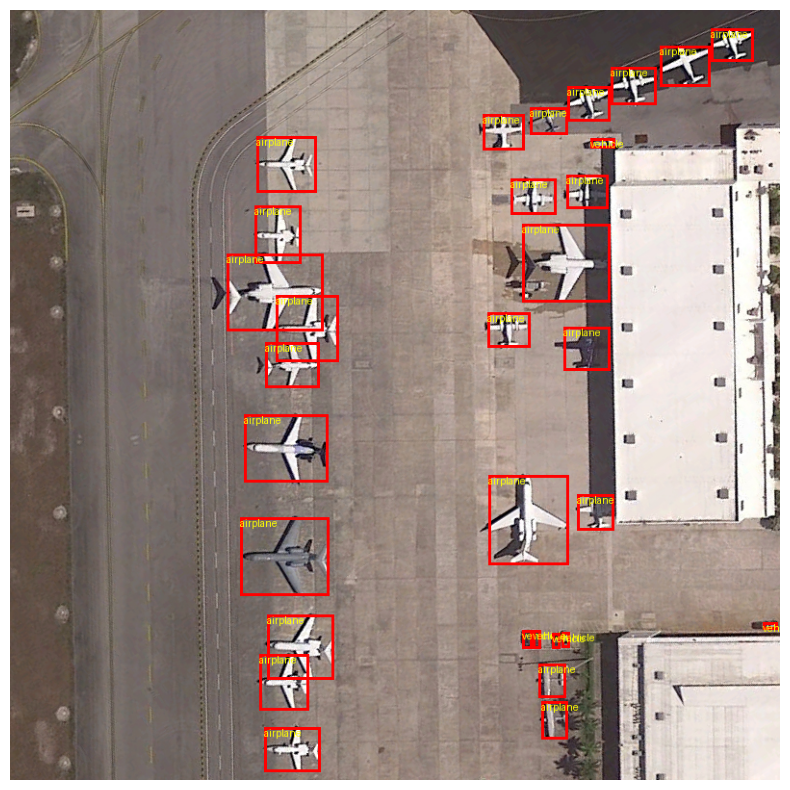

In [9]:
import os
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# ---------------------------
# 1) Paths
# ---------------------------
images_dir = "dataset/JPEGImages"
annotations_dir = "dataset/Annotations"

# pick any sample image
sample_image = "11726.jpg"     # <-- change if needed
img_path = os.path.join(images_dir, sample_image)
xml_path = os.path.join(annotations_dir, sample_image.replace(".jpg", ".xml"))

# ---------------------------
# 2) Load image
# ---------------------------
img = Image.open(img_path)
draw = ImageDraw.Draw(img)

# ---------------------------
# 3) Parse XML for bounding boxes
# ---------------------------
tree = ET.parse(xml_path)
root = tree.getroot()

for obj in root.findall("object"):
    label = obj.find("name").text

    bbox = obj.find("bndbox")
    xmin = int(bbox.find("xmin").text)
    ymin = int(bbox.find("ymin").text)
    xmax = int(bbox.find("xmax").text)
    ymax = int(bbox.find("ymax").text)

    # Draw box
    draw.rectangle([xmin, ymin, xmax, ymax], outline="red", width=3)
    draw.text((xmin, ymin), label, fill="yellow")

# ---------------------------
# 4) Show image
# ---------------------------
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.axis("off")
plt.show()

In [6]:
images_dir = 'dataset/JPEGImages'
annotations_dir = 'dataset/Annotations'
output_dir = 'dataset/YOLOv8'

class_mapping = {
    'golffield': 0,
    'Expressway-toll-station': 1,
    'vehicle': 2,
    'trainstation': 3,
    'chimney': 4,
    'storagetank': 5,
    'ship': 6,
    'harbor': 7,
    'airplane': 8,
    'groundtrackfield': 9,
    'tenniscourt': 10,
    'dam': 11,
    'basketballcourt': 12,
    'Expressway-Service-area': 13,
    'stadium': 14,
    'airport': 15,
    'baseballfield': 16,
    'bridge': 17,
    'windmill': 18,
    'overpass': 19
}

# Create output directory if not exists
os.makedirs(output_dir, exist_ok=True)

# convert bounding box coordinates to YOLO format

In [ ]:
import os
import xml.etree.ElementTree as ET


images_dir = "dataset/JPEGImages"     
annotations_dir = "dataset/Annotations"  # ملفات XML
labels_dir = "YOLO_Labels"           

os.makedirs(labels_dir, exist_ok=True)

# === DIOR CLASS MAPPING (20 classes) ===
class_mapping = {
    "airplane": 0,
    "airport": 1,
    "baseballfield": 2,
    "basketballcourt": 3,
    "bridge": 4,
    "chimney": 5,
    "dam": 6,
    "expressway-service-area": 7,
    "expressway-toll-station": 8,
    "harbor": 9,
    "golffield": 10,
    "groundtrackfield": 11,
    "overpass": 12,
    "stadium": 13,
    "storagetank": 14,
    "tenniscourt": 15,
    "trainstation": 16,
    "vehicle": 17,
    "windmill": 18,
    "ship": 19
}

# === تحويل BBox لـ YOLO ===
def convert_coordinates(size, box):
    w_img, h_img = size
    dw = 1.0 / w_img
    dh = 1.0 / h_img

    x_center = (box[0] + box[1]) / 2.0
    y_center = (box[2] + box[3]) / 2.0
    width = box[1] - box[0]
    height = box[3] - box[2]

    return (
        x_center * dw,
        y_center * dh,
        width * dw,
        height * dh
    )

# === تحويل كل XML إلى YOLO .txt ===
num_files = 0
for annotation_file in os.listdir(annotations_dir):
    if not annotation_file.endswith(".xml"):
        continue

    xml_path = os.path.join(annotations_dir, annotation_file)
    txt_path = os.path.join(labels_dir, annotation_file.replace(".xml", ".txt"))

    tree = ET.parse(xml_path)
    root = tree.getroot()

    size = root.find("size")
    width = int(size.find("width").text)
    height = int(size.find("height").text)

    lines = []

    for obj in root.iter("object"):
        cls_name = obj.find("name").text
        if cls_name not in class_mapping:
            continue
        cls_id = class_mapping[cls_name]

        xmlbox = obj.find("bndbox")
        xmin = float(xmlbox.find("xmin").text)
        ymin = float(xmlbox.find("ymin").text)
        xmax = float(xmlbox.find("xmax").text)
        ymax = float(xmlbox.find("ymax").text)

        bbox = (xmin, xmax, ymin, ymax)
        x, y, w, h = convert_coordinates((width, height), bbox)

        lines.append(f"{cls_id} {x} {y} {w} {h}\n")

    if lines:
        with open(txt_path, "w") as f:
            f.writelines(lines)
        num_files += 1

print(f" Done converting XML to YOLO. Label files created: {num_files}")
print("Classes:", class_mapping)


 Done converting XML to YOLO. Label files created: 22713
Classes: {'airplane': 0, 'airport': 1, 'baseballfield': 2, 'basketballcourt': 3, 'bridge': 4, 'chimney': 5, 'dam': 6, 'expressway-service-area': 7, 'expressway-toll-station': 8, 'harbor': 9, 'golffield': 10, 'groundtrackfield': 11, 'overpass': 12, 'stadium': 13, 'storagetank': 14, 'tenniscourt': 15, 'trainstation': 16, 'vehicle': 17, 'windmill': 18, 'ship': 19}


# split the images and YOLOv8 annotations into three folders for training, validation, and testing


In [ ]:
import shutil
import random

# ===== INPUT PATHS =====
images_dir = "dataset/JPEGImages"
labels_dir = "YOLO_Labels"

# ===== OUTPUT Folders =====
splits = ["train", "val", "test"]
for split in splits:
    os.makedirs(os.path.join(split, "images"), exist_ok=True)
    os.makedirs(os.path.join(split, "labels"), exist_ok=True)

# ===== جميع الصور التي لها label غير فارغ =====
image_files = []
for img in os.listdir(images_dir):
    if not img.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff")):
        continue

    label_path = os.path.join(labels_dir, os.path.splitext(img)[0] + ".txt")
    if os.path.exists(label_path) and os.path.getsize(label_path) > 0:
        image_files.append(img)

print("Total labeled images:", len(image_files))


SUBSET_SIZE = 800 
if SUBSET_SIZE < len(image_files):
    image_files = random.sample(image_files, SUBSET_SIZE)

random.shuffle(image_files)
n = len(image_files)

# 70% train, 15% val, 15% test
n_train = int(0.7 * n)
n_val = int(0.15 * n)
n_test = n - n_train - n_val

train_files = image_files[:n_train]
val_files = image_files[n_train:n_train + n_val]
test_files = image_files[n_train + n_val:]

split_dict = {
    "train": train_files,
    "val": val_files,
    "test": test_files
}

def copy_split(split_name, file_list):
    for img_name in file_list:
        src_img = os.path.join(images_dir, img_name)
        src_lbl = os.path.join(labels_dir, os.path.splitext(img_name)[0] + ".txt")

        dst_img = os.path.join(split_name, "images", img_name)
        dst_lbl = os.path.join(split_name, "labels", os.path.splitext(img_name)[0] + ".txt")

        shutil.copy(src_img, dst_img)
        shutil.copy(src_lbl, dst_lbl)

for split_name, files in split_dict.items():
    copy_split(split_name, files)

print(" Split done!")
print(f"Train: {len(train_files)}, Val: {len(val_files)}, Test: {len(test_files)}")


Total labeled images: 11357
 Split done!
Train: 560, Val: 120, Test: 120


# Simple EDA

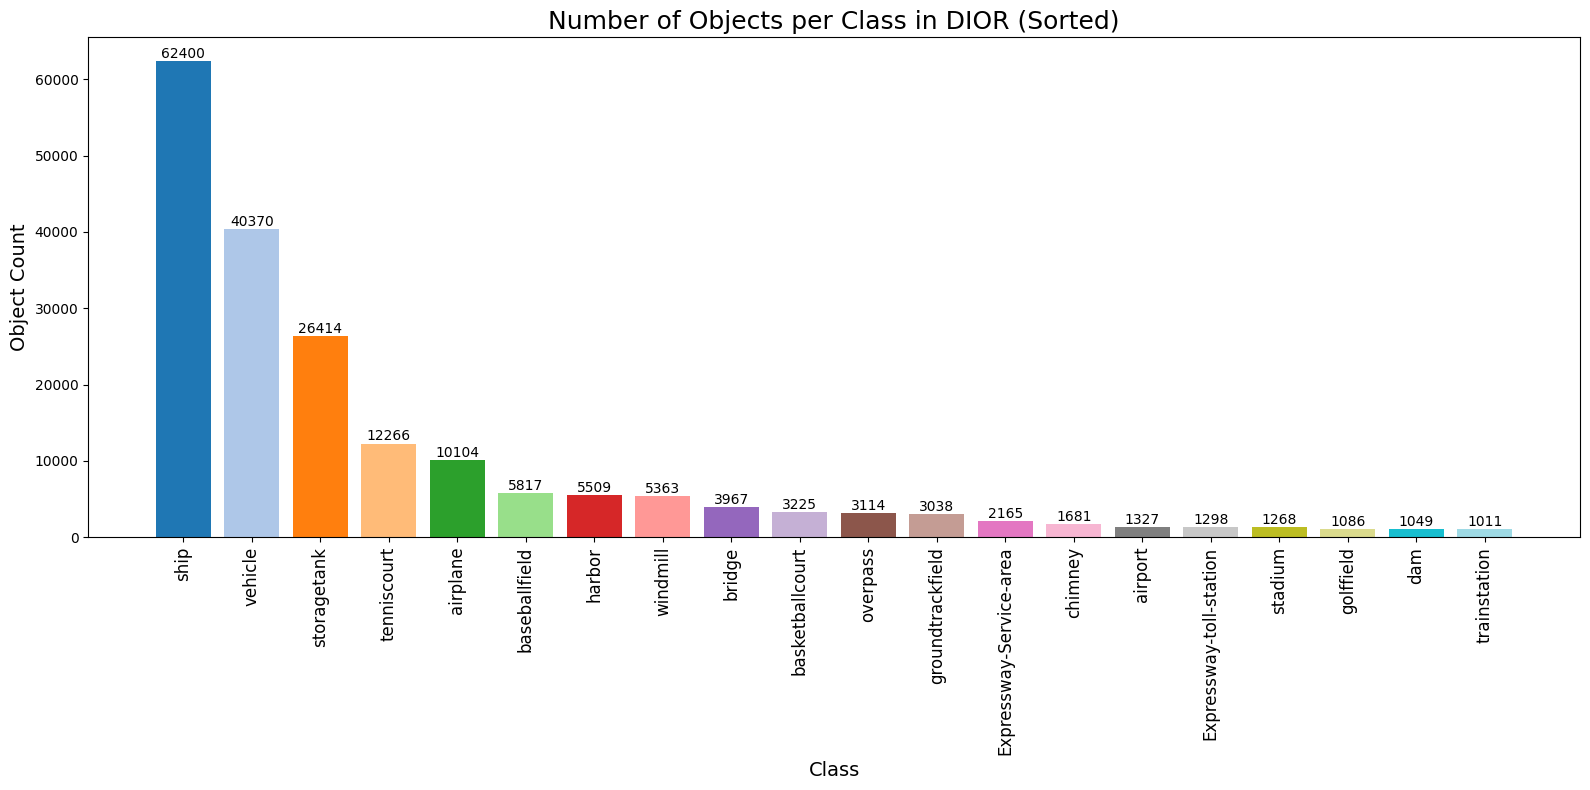

Completed! Classes sorted by number of instances:
ship: 62400
vehicle: 40370
storagetank: 26414
tenniscourt: 12266
airplane: 10104
baseballfield: 5817
harbor: 5509
windmill: 5363
bridge: 3967
basketballcourt: 3225
overpass: 3114
groundtrackfield: 3038
Expressway-Service-area: 2165
chimney: 1681
airport: 1327
Expressway-toll-station: 1298
stadium: 1268
golffield: 1086
dam: 1049
trainstation: 1011


In [13]:
class_counts = {cls: 0 for cls in class_mapping.keys()}

for annotation_file in os.listdir(annotations_dir):
    if annotation_file.endswith('.xml'):
        xml_path = os.path.join(annotations_dir, annotation_file)
        tree = ET.parse(xml_path)
        root = tree.getroot()

        for obj in root.iter('object'):
            name = obj.find('name').text
            if name in class_counts:
                class_counts[name] += 1

# ------------------------------------
# Sort counts (descending)
# ------------------------------------
sorted_items = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)
classes = [item[0] for item in sorted_items]
counts = [item[1] for item in sorted_items]

# ------------------------------------
# Plot
# ------------------------------------
plt.figure(figsize=(16, 8))
colors = plt.cm.tab20(np.linspace(0, 1, len(classes)))  # Beautiful color palette

bars = plt.bar(classes, counts, color=colors)

plt.title("Number of Objects per Class in DIOR (Sorted)", fontsize=18)
plt.xlabel("Class", fontsize=14)
plt.ylabel("Object Count", fontsize=14)
plt.xticks(rotation=90, fontsize=12)

# Add numbers on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 10,
             f"{int(height)}",
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print("Completed! Classes sorted by number of instances:")
for cls, count in sorted_items:
    print(f"{cls}: {count}")


In [16]:
# Install dependencies from requirements.txt before opening this notebook.

from ultralytics import YOLO
import matplotlib.pyplot as plt
import matplotlib.image as mpimg


# Pretrained(all layer)

In [15]:
# Model 1: Pretrained with new head
model_pretrained = YOLO("yolov8n.pt")   # load pretrained weights

results_pretrained = model_pretrained.train(
    data="data.yaml",
    epochs=10,
    imgsz=640,
    batch=4,
    project="runs/detect",
    name="train_pretrained"
)

print("Pretrained model finished training!")


Ultralytics 8.3.229  Python-3.13.5 torch-2.7.1+cpu CPU (Intel Core i3-10110U 2.10GHz)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train_pretrained, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0, pr

# Pretrained(Head only)

In [1]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data="data.yaml",
    epochs=10,
    imgsz=640,
    batch=4,
    freeze=10,     # freeze backbone
    project="runs/compare",
    name="head_only"
)


New https://pypi.org/project/ultralytics/8.3.230 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.229  Python-3.13.5 torch-2.7.1+cpu CPU (Intel Core i3-10110U 2.10GHz)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=head_only, nbs=64, nms=False, opset=None, optimize=False,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000027F6784E300>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,

In [17]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

model.train(
    data="data.yaml",
    epochs=10,
    imgsz=640,
    batch=4,
    freeze=10,     # freeze backbone
    project="runs/compare",
    name="head_only2"
)

New https://pypi.org/project/ultralytics/8.3.230 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.229  Python-3.13.5 torch-2.7.1+cpu CPU (Intel Core i3-10110U 2.10GHz)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=head_only2, nbs=64, nms=False, opset=None, optimize=False

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001A37979C320>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,

In [18]:
def evaluate_and_plot(model_path, run_name):
    print(f"\n=========== Evaluating {run_name} ===========")

    model = YOLO(model_path)
    
    # Run validation → YOLO creates a new folder in runs/detect/val*
    results = model.val(data="data.yaml", save=True)
    
    val_folder = results.save_dir
    print(f"Validation results saved in: {val_folder}")

    # --- Metrics ---
    metrics = results.results_dict
    speed = results.speed

    print("\n=== Metrics ===")
    print(f"Precision: {metrics['metrics/precision(B)']:.4f}")
    print(f"Recall:    {metrics['metrics/recall(B)']:.4f}")
    print(f"mAP50:     {metrics['metrics/mAP50(B)']:.4f}")
    print(f"mAP50-95:  {metrics['metrics/mAP50-95(B)']:.4f}")

    print("\n=== Speed (ms/img) ===")
    print(f"Inference:  {speed['inference']:.4f} ms")
    print(f"Preprocess: {speed['preprocess']:.4f} ms")
    print(f"Postprocess:{speed['postprocess']:.4f} ms")

    # --- Confusion Matrix ---
    cm_path = f"{val_folder}/confusion_matrix.png"
    if os.path.exists(cm_path):
        plt.figure(figsize=(12, 10))
        img = mpimg.imread(cm_path)
        plt.imshow(img)
        plt.title(f"{run_name} - Confusion Matrix")
        plt.axis("off")
        plt.show()
    else:
        print("⚠️ confusion_matrix.png NOT FOUND")

    # --- Curves (correct names for DIOR Detection) ---
    curve_files = [
        "BoxF1_curve.png",
        "BoxP_curve.png",
        "BoxR_curve.png",
        "BoxPR_curve.png"
    ]

    fig, axs = plt.subplots(2, 2, figsize=(15, 12))
    
    for ax, fname in zip(axs.ravel(), curve_files):
        fpath = f"{val_folder}/{fname}"

        if os.path.exists(fpath):
            img = mpimg.imread(fpath)
            ax.imshow(img)
            ax.set_title(fname.replace(".png", ""))
            ax.axis("off")
        else:
            ax.text(0.5, 0.5, f"{fname} NOT FOUND", ha='center', fontsize=14)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

    # --- Validation vs Predictions ---
    fig, axs = plt.subplots(1, 2, figsize=(18, 10))

    labels_img_path = f"{val_folder}/val_batch0_labels.jpg"
    pred_img_path   = f"{val_folder}/val_batch0_pred.jpg"

    if os.path.exists(labels_img_path):
        labels_img = mpimg.imread(labels_img_path)
        axs[0].imshow(labels_img)
        axs[0].set_title(f"{run_name} - Validation Labels")
        axs[0].axis("off")
    else:
        axs[0].text(0.5, 0.5, "val_batch0_labels.jpg NOT FOUND", ha="center")
        axs[0].axis("off")

    if os.path.exists(pred_img_path):
        pred_img = mpimg.imread(pred_img_path)
        axs[1].imshow(pred_img)
        axs[1].set_title(f"{run_name} - Predictions")
        axs[1].axis("off")
    else:
        axs[1].text(0.5, 0.5, "val_batch0_pred.jpg NOT FOUND", ha="center")
        axs[1].axis("off")

    plt.tight_layout()
    plt.show()


In [19]:
evaluate_and_plot(
    "runs/compare/head_only2/weights/best.pt",
    "head_only2"
)


=========== Evaluating head_only2 ===========
Ultralytics 8.3.229  Python-3.13.5 torch-2.7.1+cpu CPU (Intel Core i3-10110U 2.10GHz)
Model summary (fused): 72 layers, 11,133,324 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 1334.6489.4 MB/s, size: 246.5 KB)
val: Scanning <local-dior>\val\labels.cache... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 151.9Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 5.3s/it 42.8s6.2ss
                   all        120       1382      0.655      0.447      0.534      0.344
              airplane          9        225      0.881      0.492      0.662      0.329
               airport          6          7      0.658      0.143        0.3      0.167
         baseballfield          7         19      0.743      0.632      0.693      0.556
       basketballcourt         11         46      0.672       0.87      0.895      0.667


<Figure size 1200x1000 with 1 Axes>

<Figure size 1500x1200 with 4 Axes>

<Figure size 1800x1000 with 2 Axes>

In [5]:
evaluate_and_plot(
    "runs/compare/head_only/weights/best.pt",
    "head_only"
)


=========== Evaluating head_only ===========
Ultralytics 8.3.229  Python-3.13.5 torch-2.7.1+cpu CPU (Intel Core i3-10110U 2.10GHz)
Model summary (fused): 72 layers, 3,009,548 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 1328.1434.1 MB/s, size: 309.6 KB)
val: Scanning <local-dior>\val\labels.cache... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 159.2Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.3s/it 18.1s2.6s
                   all        120       1382       0.52      0.357       0.37      0.231
              airplane          9        225      0.874      0.246      0.407      0.212
               airport          6          7      0.296      0.286      0.252      0.152
         baseballfield          7         19      0.692      0.632      0.632      0.502
       basketballcourt         11         46      0.531      0.674      0.654      0.453
    

<Figure size 1200x1000 with 1 Axes>

<Figure size 1500x1200 with 4 Axes>

<Figure size 1800x1000 with 2 Axes>

In [26]:
evaluate_and_plot(
    "runs/detect/train_pretrained/weights/best.pt",
    "train_pretrained"
)



=========== Evaluating train_pretrained ===========
Ultralytics 8.3.229  Python-3.13.5 torch-2.7.1+cpu CPU (Intel Core i3-10110U 2.10GHz)
Model summary (fused): 72 layers, 3,009,548 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 761.2321.0 MB/s, size: 136.7 KB)
val: Scanning <local-dior>\val\labels.cache... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 103.0Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.3s/it 18.2s2.6ss
                   all        120       1356      0.604      0.417      0.451      0.312
              airplane          6         54      0.853      0.643      0.786      0.491
               airport          5          5          0          0     0.0477     0.0282
         baseballfield         12         45      0.885      0.858      0.889      0.742
       basketballcourt         11         41      0.799      0.585      0.625      0.5

<Figure size 1200x1000 with 1 Axes>

<Figure size 1500x1200 with 4 Axes>

<Figure size 1800x1000 with 2 Axes>